# Jev alone as a judge — direct TypeSafe API

A routing agent assigns an intent to a user's request. Human reviewers identify mistakes
by comparing that prediction with the expected intent, then categorize the mistakes.
We focus on **Vague Utterance**: a routing mistake caused by an ambiguous request or
missing information.

We ask Jev to automate the check: **“Is this routing result a Vague Utterance failure?”**
The reviewers' labels let us check its answers. We will first explain the labeled examples,
then run Jev and measure the failures it finds, its false alarms, and its API cost.

Jev is a candidate for a quick, narrow “System 1” judgment: it returns a typed decision
without generating an explanation. See [TypeSafe's introduction](https://docs.typesafe.ai/introduction).
The [Jev/LLM comparison](llm_as_judge.ipynb) extends this approach with an independent LLM
judge, called when Jev's answer has low confidence or is invalid.

Saved results are included. To run Jev again, provide `TYPESAFE_API_KEY`, or replay a run
you previously saved locally. Setup details are in the [README](../README.md).

In [1]:
# Run from this directory, the repository root, or a fresh Colab runtime.
import os, sys, subprocess
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_REF = os.environ.get("ROUTING_EVALS_REF", "codex/jev-routing-judge")
candidates = [Path.cwd(), Path.cwd() / "routing_agent_evals",
              Path.cwd() / "AI-Evals-Principles/routing_agent_evals"]
LAB = next((p for p in candidates if (p / "judge_lab.py").exists()), None)
if LAB is None and IN_COLAB:
    checkout = Path("/content/routing-evals-lab")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_REF,
                        "https://github.com/The-Gen-Academy/Mastering-Agentic-AI-Week4-Session1.git",
                        str(checkout)], check=True)
    LAB = checkout / "AI-Evals-Principles/routing_agent_evals"
if LAB is None or not (LAB / "judge_lab.py").exists():
    raise RuntimeError("Open the notebook from its repository checkout; see README for setup.")
LAB = LAB.resolve()
os.chdir(LAB)
sys.path.insert(0, str(LAB))
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pandas", "scikit-learn", "matplotlib", "python-dotenv"], check=True)

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
from judge_lab import (JudgeClient, load_dataset, batch, metrics,
                       always_false, request_for, save_json, digest, POLICY, CRITERIA,
                       JUDGE_DATA_SOURCE)

load_dotenv(LAB / ".env", override=False)
RUN = Path(os.environ.get("JEV_RUN_DIR", str(LAB / ".runs/jev")))
EVIDENCE = Path(os.environ.get("JUDGE_EVIDENCE_DIR", str(RUN)))
MODE = os.environ.get("JEV_MODE", "replay" if (EVIDENCE / "jev_manifest.json").exists() else "live")
assert MODE in {"replay", "live"}
RUN.mkdir(parents=True, exist_ok=True)
manifest = json.loads((EVIDENCE / "jev_manifest.json").read_text()) if MODE == "replay" else {}
client = JudgeClient(EVIDENCE / "cache" if MODE == "replay" else RUN / "cache",
                     live=(MODE == "live"), providers=manifest.get("providers"),
                     models=manifest.get("models"), pricing=manifest.get("pricing"))
if MODE == "live":
    key = os.environ.get("TYPESAFE_API_KEY")
    if not key and IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get("TYPESAFE_API_KEY")
        except Exception:
            pass
    if not key:
        from getpass import getpass
        key = getpass("TYPESAFE_API_KEY (hidden, never saved): ").strip()
    client.api_keys["jev"] = key
print("Mode:", MODE, "| Jev model:", client.models["jev"], "| provider:", client.providers["jev"])

Mode: replay | Jev model: jev-1.13.0 | provider: typesafe


## The examples and the question Jev answers

Human reviewers compared the expected and predicted intents for 300 routing examples.
They found **52 routing failures**, then assigned those failures to categories:
**20 Vague Utterance failures** and **32 other failures**. The remaining **248 examples
were correctly routed**.

The `Vague_Utterance_Failure` column records `TRUE` for the 20 Vague Utterance failures
and `FALSE` for the other 280 examples. These are the human answers we compare Jev against.

For each row, Jev receives the user request, the router's predicted intent, and the rules
for identifying a Vague Utterance failure. It returns `TRUE` or `FALSE`, which we compare
with the human label. The human label, target intent, comments, and failure category are
hidden from Jev.

We include correctly routed requests because Jev could incorrectly flag one as a failure.
That lets us count false alarms as well as Vague Utterance failures found or missed.

We ask Jev to judge all **300 examples** and compare its answers with their human labels.
The next notebook uses these same 300 examples to compare Jev, the LLM, and a Jev-first
policy with a fixed confidence cutoff of **0.7**.

In [3]:
rows = load_dataset(LAB / "data")
display(pd.DataFrame([{"examples": len(rows),
                      "Vague Utterance failures": sum(r["human_label"] == "TRUE" for r in rows),
                      "other examples": sum(r["human_label"] == "FALSE" for r in rows)}]))
example_request = request_for(rows[0], "jev", client.models["jev"])
print("State sent to Jev:", example_request["state"])
assert set(example_request["state"]) == {"user_query", "predicted_intent"}
display(pd.DataFrame([{"choice": k, "criterion": v} for k, v in CRITERIA.items()]))

,examples,Vague Utterance failures,other examples
0,300,20,280


State sent to Jev: {'user_query': 'How many patients did I see last month?', 'predicted_intent': 'IRRELEVANT_QUERY'}


,choice,criterion
0,TRUE,The predicted intent is wrong specifically bec...
1,FALSE,"The predicted intent is correct, or it is wron..."


## Jev chooses a label; confidence controls review

Jev uses **Choice** to select between `TRUE` and `FALSE`. It returns the chosen label,
the probability of each option, and a confidence value. The label answers the
failure-category question; confidence tells us how strongly Jev favors that answer.
Choice returns a category, whereas **Score** evaluates ordered rating levels.

Jev assigns probabilities to `TRUE` and `FALSE` that add to 1. The **winning probability**
is the probability of the chosen option. For this two-option Choice, **confidence is the
gap between those probabilities**: a 50/50 split gives confidence 0, while 100/0 gives 1.

Suppose Jev returns `TRUE: 0.85` and `FALSE: 0.15`. It chooses `TRUE`, with winning
probability **0.85** and confidence **0.85 − 0.15 = 0.70**. This is equivalent to
`confidence = 2 × winning_probability − 1`.

The comparison notebook keeps Jev's answer when confidence is at least 0.7. A 0.85/0.15
split meets that cutoff; a 0.70/0.30 split has confidence 0.40 and goes to the LLM instead.
The rule works for either chosen label. These are model estimates, not measured accuracy.
See [Choice](https://docs.typesafe.ai/primitives/choice) and
[confidence](https://docs.typesafe.ai/confidence).

In [4]:
jev = batch(rows, lambda r: client.call(r, "jev"))
display(pd.DataFrame([jev[rows[0]["id"]]]))
comparison = pd.DataFrame([metrics(rows, values, name) for name, values in
                          [("Always FALSE", always_false(rows)), ("Jev alone", jev)]])
display(comparison[["method", "n", "accuracy", "precision_TRUE", "recall_TRUE", "f1_TRUE",
                    "TN", "FP", "FN_including_unresolved", "TP", "unresolved"]])
comparison.to_csv(RUN / "jev-comparison.csv", index=False)

,id,stage,request_hash,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,attempts,elapsed_seconds,input_tokens,output_tokens,label,error,confidence,probabilities,model
0,TEST_009,jev,d508cd78336e6779d69ea84e5711b0df88ae49d4fc178d...,0.000055,0,0.000055,1,0,1,1,0.091085,1320,33,FALSE,None,0.88,"{'TRUE': 0.06, 'FALSE': 0.94}",jev-1.13.0


,method,n,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved
0,Always FALSE,300,0.933333,0.0,0.0,0,280,0,20,0,0
1,Jev alone,300,0.893333,0.0,0.0,0,268,12,20,0,0


## Token usage and estimated cost

TypeSafe returned input/output token counts without a billed USD amount. The published
Jev 1.13 rate, checked 2026-10-22, is **$0.042 per million input tokens; output tokens are
free**. We freeze that rate and its [source](https://docs.typesafe.ai/models) in the manifest.
`estimated_cost_usd` is token usage multiplied by this rate, not an invoice; credits and
account-specific discounts are excluded. `reported_cost_usd` records any explicit provider
charge. Missing usage or an unknown model price remains unknown, never zero by assumption.

The comparison notebook uses `Jev cost for all rows + LLM cost for escalated rows` for
cascade deployment cost. The three-way comparison also obtains standalone LLM answers
on every row. This Jev-only notebook cannot establish cascade savings or quality.

,method,n,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,USD_per_1000_including_estimates
0,All Jev requests,300,0,0.016651,300,0,0.055504


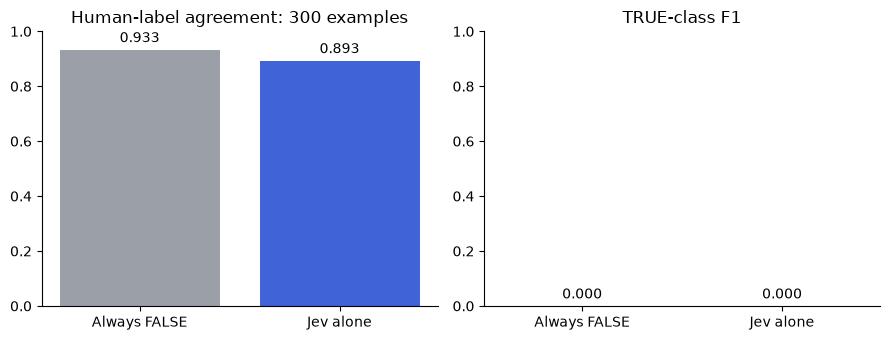

In [5]:
costs = pd.DataFrame([metrics(rows, jev, "All Jev requests")])
costs["USD_per_1000_including_estimates"] = costs.cost_usd / costs.n * 1000
display(costs[["method", "n", "reported_cost_usd", "estimated_cost_usd",
               "estimated_cost_attempts", "unknown_cost_attempts", "USD_per_1000_including_estimates"]])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, field, title in zip(axes, ["accuracy", "f1_TRUE"], ["Human-label agreement: 300 examples", "TRUE-class F1"]):
    bars = ax.bar(comparison.method, comparison[field], color=["#9a9fa8", "#4063d8"])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Read the result before adopting the judge

Jev agrees with **268/300 human labels (89.3%)**, but finds **0 of the 20** Vague Utterance
failures. Always answering `FALSE` agrees with **280/300 labels (93.3%)** and also finds
none of those failures. This is why we need failure recall and F1 alongside agreement.
The estimated cost of all 300 Jev requests is **$0.01665**.

These results do not support using Jev alone to detect this failure category. In the
[comparison notebook](llm_as_judge.ipynb), we ask the LLM when Jev's confidence is below
**0.7** or its output is invalid. That fixed policy sends **59/300** cases to the LLM and
finds **10/20** Vague Utterance failures. It also creates more false alarms than Jev alone.
Read the comparison for the full quality and cost tradeoff.

These measurements describe the 300 labeled examples. Check the policy on new
human-reviewed examples before relying on it in an application.

In [6]:
summary = {"dataset_hash": digest(rows), "dataset_source": JUDGE_DATA_SOURCE,
           "policy_hash": digest([POLICY, CRITERIA]), **client.configuration(),
           "evaluation_ids": [r["id"] for r in rows],
           "dataset_metrics": metrics(rows, jev, "Jev alone")}
if MODE == "replay":
    for field in ("dataset_hash", "dataset_source", "policy_hash", "evaluation_ids", "dataset_metrics"):
        assert summary[field] == manifest[field], field
    assert client.new_requests == 0
else:
    save_json(RUN / "jev_manifest.json", summary)
save_json(RUN / "summary.json", summary)
print("Jev notebook complete; fresh HTTP requests:", client.new_requests)
print("Outputs:", RUN)

Jev notebook complete; fresh HTTP requests: 0
Outputs: routing_agent_evals/.runs/jev
